# How to plot grids with matplotlib

Note that geopandas is not required for plotting grids.

## Code setup

In [1]:
import os
from dataclasses import dataclass

# Load data:
import numpy as np  # to load grids
import json  # to load dict
import geojson  # to load and save outlines

# Plotting:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import cmasher as cmr  # extra colour maps
import shapely.plotting  # to plot outlines

# Add path to package:
import sys
sys.path.insert(0,'../')
import isopods.outline
import isopods.convert

In [2]:
@dataclass(frozen=True)
class Paths:
    '''Singleton object for storing paths to data and database.'''

    dir_data: str = '../data'

    dict_filename: str = 'lsoa2011_devon_1k_grid_dict.json'
    lsoa_grid_data_filename: str = 'lsoa2011_devon_1k_grid_data.csv'
    lsoa_grid_mask_filename: str = 'lsoa2011_devon_1k_grid_mask.csv'
    district_grid_data_filename: str = 'district2011_devon_1k_grid_data.csv'
    district_grid_mask_filename: str = 'district2011_devon_1k_grid_mask.csv'
    outline_filename: str = 'districts2011_devon_1k_outlines.geojson'

paths = Paths()

## Load data

In [3]:
# Grid dictionary
p = os.path.join(paths.dir_data, paths.dict_filename)
with open(p, 'r') as f:
    transform_dict = json.load(f)

# Grid array
# LSOA-level:
p_d = os.path.join(paths.dir_data, paths.lsoa_grid_data_filename)
p_m = os.path.join(paths.dir_data, paths.lsoa_grid_mask_filename)
lsoa_grid_data = np.loadtxt(p_d, dtype=str, delimiter=',')
lsoa_grid_mask = np.loadtxt(p_m, dtype=bool, delimiter=',')
arr_lsoa = np.ma.MaskedArray(
    lsoa_grid_data, mask=lsoa_grid_mask, dtype=object)
# District level:
p_d = os.path.join(paths.dir_data, paths.district_grid_data_filename)
p_m = os.path.join(paths.dir_data, paths.district_grid_mask_filename)
district_grid_data = np.loadtxt(p_d, dtype=str, delimiter=',')
district_grid_mask = np.loadtxt(p_m, dtype=bool, delimiter=',')
arr_districts = np.ma.MaskedArray(
    district_grid_data, mask=district_grid_mask, dtype=object)

# Outlines
p = os.path.join(paths.dir_data, paths.outline_filename)
with open(p, 'r') as f:
    gj = geojson.load(f)
dict_polys = isopods.outline.convert_featurecollection_to_dict_polys(gj)

## Setup for plots

Grid extent:

In [4]:
# For plotting the grid with imshow:
extent = (transform_dict['xmin'], transform_dict['xmax'],
          transform_dict['ymin'], transform_dict['ymax'])

Assign random values to LSOA:

In [5]:
# Convert to grid containing this data:
try:
    labels_unique = np.unique(arr_lsoa.compressed())  # masked array
except AttributeError:
    labels_unique = np.unique(arr_lsoa)  # normal array
np.random.seed(42)
np.random.shuffle(labels_unique)
dict_labels_to_data = dict(zip(labels_unique, range(len(labels_unique))))

arr_lsoa_values = isopods.convert.convert_grid_values(
    arr_lsoa, dict_labels_to_data)

Generate colours for districts.

In [6]:
# Convert to grid containing this data:
try:
    labels_unique = np.unique(arr_districts.compressed())  # masked array
except AttributeError:
    labels_unique = np.unique(arr_districts)  # normal array
colours = plt.get_cmap('cmr.rainforest_r')(
    np.linspace(0.1, 0.9, len(labels_unique)))
dict_place_colours = dict(zip(labels_unique, colours))

# Check that these colours are in either RGB or RGBA tuple format:
print('Colour type:', type(list(dict_place_colours.values())[0]))

# Make some patches for a pyplot legend:
legend_elements = [
    Patch(facecolor=colour, edgecolor='k', label=place)
    for place, colour in dict_place_colours.items()
]

arr_districts_values = isopods.convert.convert_grid_values(
    arr_districts, dict_place_colours)

Colour type: <class 'numpy.ndarray'>


## Plots

### imshow with continuous data

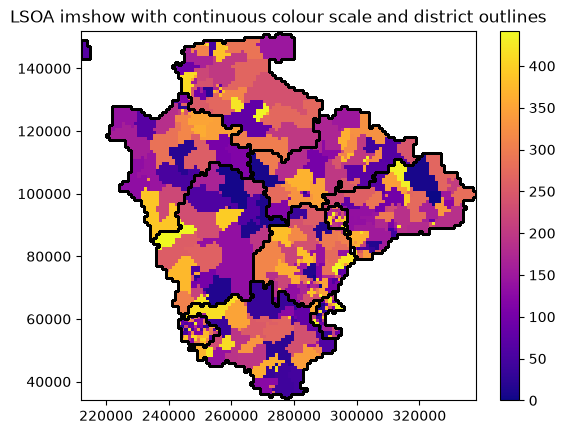

In [7]:
fig, ax = plt.subplots()

# Draw gridded data:
cmap = plt.get_cmap('plasma')
cl = ax.imshow(arr_lsoa_values, origin='lower', extent=extent,
               interpolation='None', cmap=cmap)
plt.colorbar(cl)

# Overlay outlines:
for region, poly in dict_polys.items():
    # Convert polygon to a matplotlib patch:
    # Need antialiased=False to make borders appear to line up with
    # grid. Underlying shapes fine, but antialiased=True makes them
    # look offset in places.
    p = shapely.plotting.patch_from_polygon(
        poly, facecolor=(0, 0, 0, 0), edgecolor='k', antialiased=False
    )
    ax.add_patch(p)

ax.set_title('LSOA imshow with continuous colour scale '
             'and district outlines')
plt.show()

### imshow with colour lookup

The data array must be of shape:
+ (Y, X, 3) for RGB colour tuples, or
+ (Y, X, 4) for RGBA colour tuples

Each layer of shape (Y, X) contains one of the colour values, e.g. the first (Y, X) grid contains only the red values.

In [8]:
print(transform_dict['n_rows'], transform_dict['n_cols'])
print(arr_districts_values.shape)

118 126
(118, 126, 4)


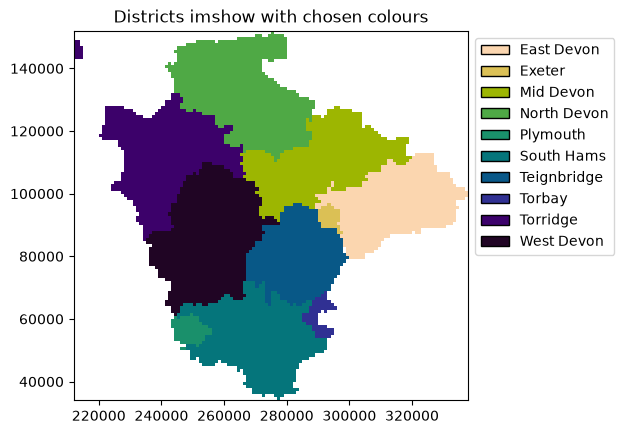

In [9]:
fig, ax = plt.subplots()

# Gridded data:
cl = ax.imshow(arr_districts_values, origin='lower', extent=extent,
               interpolation='None')
# Use legend defined from the colour dictionary:
ax.legend(handles=legend_elements, bbox_to_anchor=(1.0, 1.0),
          loc='upper left')

ax.set_title('Districts imshow with chosen colours')

plt.show()

### Filled polygons only

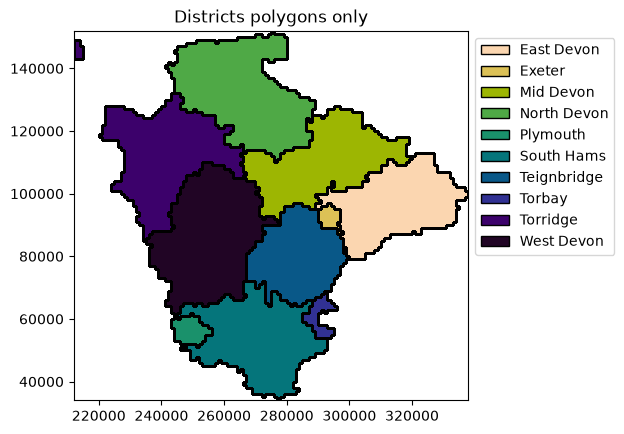

In [10]:
fig, ax = plt.subplots()

# Overlay outlines:
for region, poly in dict_polys.items():
    # Convert polygon to a matplotlib patch:
    # Need antialiased=False to make borders appear to line up with
    # grid. Underlying shapes fine, but antialiased=True makes them
    # look offset in places.
    colour = dict_place_colours[region]
    p = shapely.plotting.patch_from_polygon(
        poly, antialiased=False, facecolor=colour, edgecolor='k',
        label=region
    )
    ax.add_patch(p)
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left')

# If only polygons have been plotted, then
# make sure the limits cover the patch locations!
ax.set_xlim(transform_dict['xmin'], transform_dict['xmax'])
ax.set_ylim(transform_dict['ymin'], transform_dict['ymax'])
ax.set_aspect('equal')

ax.set_title('Districts polygons only')
plt.show()